In [1]:
!pip -q install pykrige geopandas rasterio

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
import zipfile

from google.colab import files
from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.transform import from_bounds
from scipy.optimize import curve_fit
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)
from pykrige.ok import OrdinaryKriging

# Subir ZIP
subidos = files.upload()
archivo_zip = next(iter(subidos))

with zipfile.ZipFile(archivo_zip) as archivo:
    archivo.extractall('datos_ndvi')

shp = 'datos_ndvi/ndvi_data/ndvi.shp'
tif = 'datos_ndvi/ndvi_data/ndvi.tif'

# Datos espaciales
puntos = gpd.read_file(shp).to_crs('EPSG:32718')

x = puntos.geometry.x.to_numpy()
y = puntos.geometry.y.to_numpy()
z = puntos['first'].to_numpy(dtype=float)

# Bounding box del TIFF
with rasterio.open(tif) as raster:
    xmin, ymin, xmax, ymax = transform_bounds(
        raster.crs,
        'EPSG:32718',
        *raster.bounds
    )

print('Observaciones:', len(z))
print('NDVI mínimo:', z.min())
print('NDVI máximo:', z.max())
print('Bounding box:', xmin, ymin, xmax, ymax)

Saving datos_ndvi_para_colab.zip to datos_ndvi_para_colab.zip
Observaciones: 300
NDVI mínimo: -0.18525702787229
NDVI máximo: 0.869773131363612
Bounding box: 198631.04124416714 8805880.667101948 209661.93739883538 8814836.344230773


## Variograma experimental

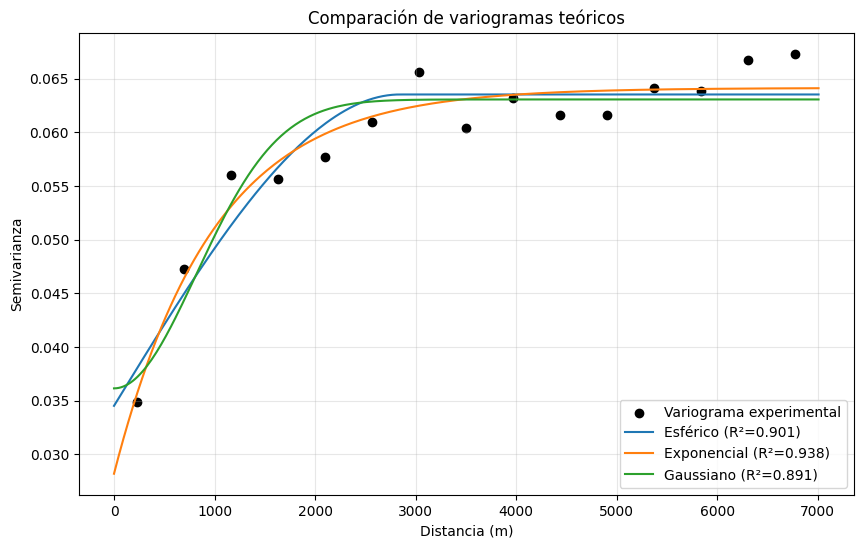

,nugget,sill,rango,r2,rmse
Esférico,0.03451,0.06354,2843.95250,0.90076,0.00257
Exponencial,0.02818,0.06415,2958.33234,0.93828,0.00203
Gaussiano,0.03614,0.06308,2000.42720,0.89101,0.00270


In [2]:
def variograma_experimental(x, y, z, max_lag=70, n_bins=15):
    bins = np.linspace(0, max_lag, n_bins + 1)
    gamma = np.zeros(len(bins) - 1)
    pairs = np.zeros(len(bins) - 1)

    for i in range(len(x)):
        distances = np.sqrt(
            (x[i] - x[i+1:])**2 +
            (y[i] - y[i+1:])**2
        )
        variances = 0.5 * (z[i] - z[i+1:])**2

        for k in range(len(bins) - 1):
            mask = (
                (distances >= bins[k]) &
                (distances < bins[k+1])
            )

            if np.any(mask):
                gamma[k] += np.sum(variances[mask])
                pairs[k] += np.sum(mask)

    valid = pairs > 0
    dist_clean = (bins[:-1] + bins[1:]) / 2

    return dist_clean[valid], gamma[valid] / pairs[valid]


def modelo_esferico(h, nugget, sill, range_val):
    h = np.maximum(h, 1e-10)
    return np.where(
        h <= range_val,
        nugget + (sill - nugget) *
        (1.5*h/range_val - 0.5*(h/range_val)**3),
        sill
    )


def modelo_exponencial(h, nugget, sill, range_val):
    h = np.maximum(h, 1e-10)
    return nugget + (sill - nugget) * (
        1 - np.exp(-3*h/range_val)
    )


def modelo_gaussiano(h, nugget, sill, range_val):
    h = np.maximum(h, 1e-10)
    return nugget + (sill - nugget) * (
        1 - np.exp(-3*(h/range_val)**2)
    )


# Variograma experimental
max_lag = np.sqrt(
    (x.max()-x.min())**2 +
    (y.max()-y.min())**2
) / 2

n_bins = 15

dist_exp, gamma_exp = variograma_experimental(
    x, y, z,
    max_lag=max_lag,
    n_bins=n_bins
)

# Modelos teóricos
modelos = {
    'Esférico': modelo_esferico,
    'Exponencial': modelo_exponencial,
    'Gaussiano': modelo_gaussiano
}

sill_est = np.var(z)

p0 = [
    0.1*sill_est,
    sill_est,
    0.6*dist_exp.max()
]

bounds = (
    [0, 0, 1],
    [max(sill_est*3, 0.01),
     max(sill_est*3, 0.01),
     dist_exp.max()*2]
)

resultados = {}
dist_cont = np.linspace(0, max_lag, 300)

plt.figure(figsize=(10, 6))

plt.scatter(
    dist_exp, gamma_exp,
    color='black',
    label='Variograma experimental'
)

for nombre, modelo in modelos.items():

    popt, _ = curve_fit(
        modelo,
        dist_exp,
        gamma_exp,
        p0=p0,
        bounds=bounds,
        maxfev=20000
    )

    gamma_pred = modelo(dist_exp, *popt)

    r2 = r2_score(gamma_exp, gamma_pred)
    rmse = np.sqrt(
        mean_squared_error(gamma_exp, gamma_pred)
    )

    resultados[nombre] = {
        'nugget': popt[0],
        'sill': popt[1],
        'rango': popt[2],
        'r2': r2,
        'rmse': rmse
    }

    plt.plot(
        dist_cont,
        modelo(dist_cont, *popt),
        label=f'{nombre} (R²={r2:.3f})'
    )

plt.xlabel('Distancia (m)')
plt.ylabel('Semivarianza')
plt.title('Comparación de variogramas teóricos')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

display(pd.DataFrame(resultados).T.round(5))

# Kriging con los 3 modelos

In [3]:
# Grilla de predicción
nx, ny = 120, 100

gridx = xmin + (np.arange(nx) + 0.5) * (xmax - xmin) / nx
gridy = ymin + (np.arange(ny) + 0.5) * (ymax - ymin) / ny

# TIFF sobre la misma grilla
ref = np.full((ny, nx), np.nan, dtype=np.float32)

with rasterio.open(tif) as raster:
    reproject(
        source=rasterio.band(raster, 1),
        destination=ref,
        src_transform=raster.transform,
        src_crs=raster.crs,
        src_nodata=raster.nodata,
        dst_transform=from_bounds(
            xmin, ymin, xmax, ymax, nx, ny
        ),
        dst_crs='EPSG:32718',
        dst_nodata=np.nan,
        resampling=Resampling.nearest
    )

ref = np.flipud(ref)

valido = (
    np.isfinite(ref) &
    (ref >= -1) &
    (ref <= 1)
)

# Kriging para cada variograma
predicciones_ok = {}
varianzas_ok = {}
metricas_ok = []

for nombre, param in resultados.items():

    modelo_pykrige = {
        'Esférico': 'spherical',
        'Exponencial': 'exponential',
        'Gaussiano': 'gaussian'
    }[nombre]

    nugget = param['nugget']
    sill = param['sill']
    rango = param['rango']

    if sill < nugget:
        print(nombre, ': sill menor que nugget; revisar ajuste')
        continue

    # Conversión del rango gaussiano
    if nombre == 'Gaussiano':
        rango = rango * 7 / (4 * np.sqrt(3))

    ok = OrdinaryKriging(
        x, y, z,
        variogram_model=modelo_pykrige,
        variogram_parameters={
            'sill': sill,
            'range': rango,
            'nugget': nugget
        },
        verbose=False,
        enable_plotting=False
    )

    # Predicción
    Z_ok, V_ok = ok.execute(
        'grid', gridx, gridy
    )

    Z_ok = np.asarray(Z_ok.filled(np.nan)) if np.ma.isMaskedArray(Z_ok) else np.asarray(Z_ok)
    V_ok = np.asarray(V_ok)

    predicciones_ok[nombre] = Z_ok
    varianzas_ok[nombre] = V_ok

    # Error frente al TIFF
    mask = valido & np.isfinite(Z_ok)

    observado = ref[mask]
    predicho = Z_ok[mask]

    rmse = np.sqrt(
        mean_squared_error(observado, predicho)
    )

    mae = mean_absolute_error(
        observado, predicho
    )

    r2 = r2_score(
        observado, predicho
    )

    sesgo = np.mean(predicho - observado)

    metricas_ok.append({
        'Modelo': nombre,
        'RMSE': rmse,
        'MAE': mae,
        'R2_prediccion': r2,
        'Sesgo': sesgo,
        'R2_variograma': param['r2'],
        'Nugget': nugget,
        'Sill': sill,
        'Rango': param['rango']
    })

# Resultados
comparacion_ok = pd.DataFrame(metricas_ok)
comparacion_ok = comparacion_ok.sort_values('RMSE')

display(comparacion_ok.round(5))

mejor_modelo = comparacion_ok.iloc[0]['Modelo']

print('Mejor modelo:', mejor_modelo)
print('RMSE:', comparacion_ok.iloc[0]['RMSE'])

,Modelo,RMSE,MAE,R2_prediccion,Sesgo,R2_variograma,Nugget,Sill,Rango
1,Exponencial,0.19974,0.15018,0.39809,-0.00774,0.93828,0.02818,0.06415,2958.33234
0,Esférico,0.20363,0.15444,0.37439,-0.00647,0.90076,0.03451,0.06354,2843.95250
2,Gaussiano,0.20569,0.15552,0.36169,-0.00613,0.89101,0.03614,0.06308,2000.42720


Mejor modelo: Exponencial
RMSE: 0.19973959519402917


# Comparación Visual

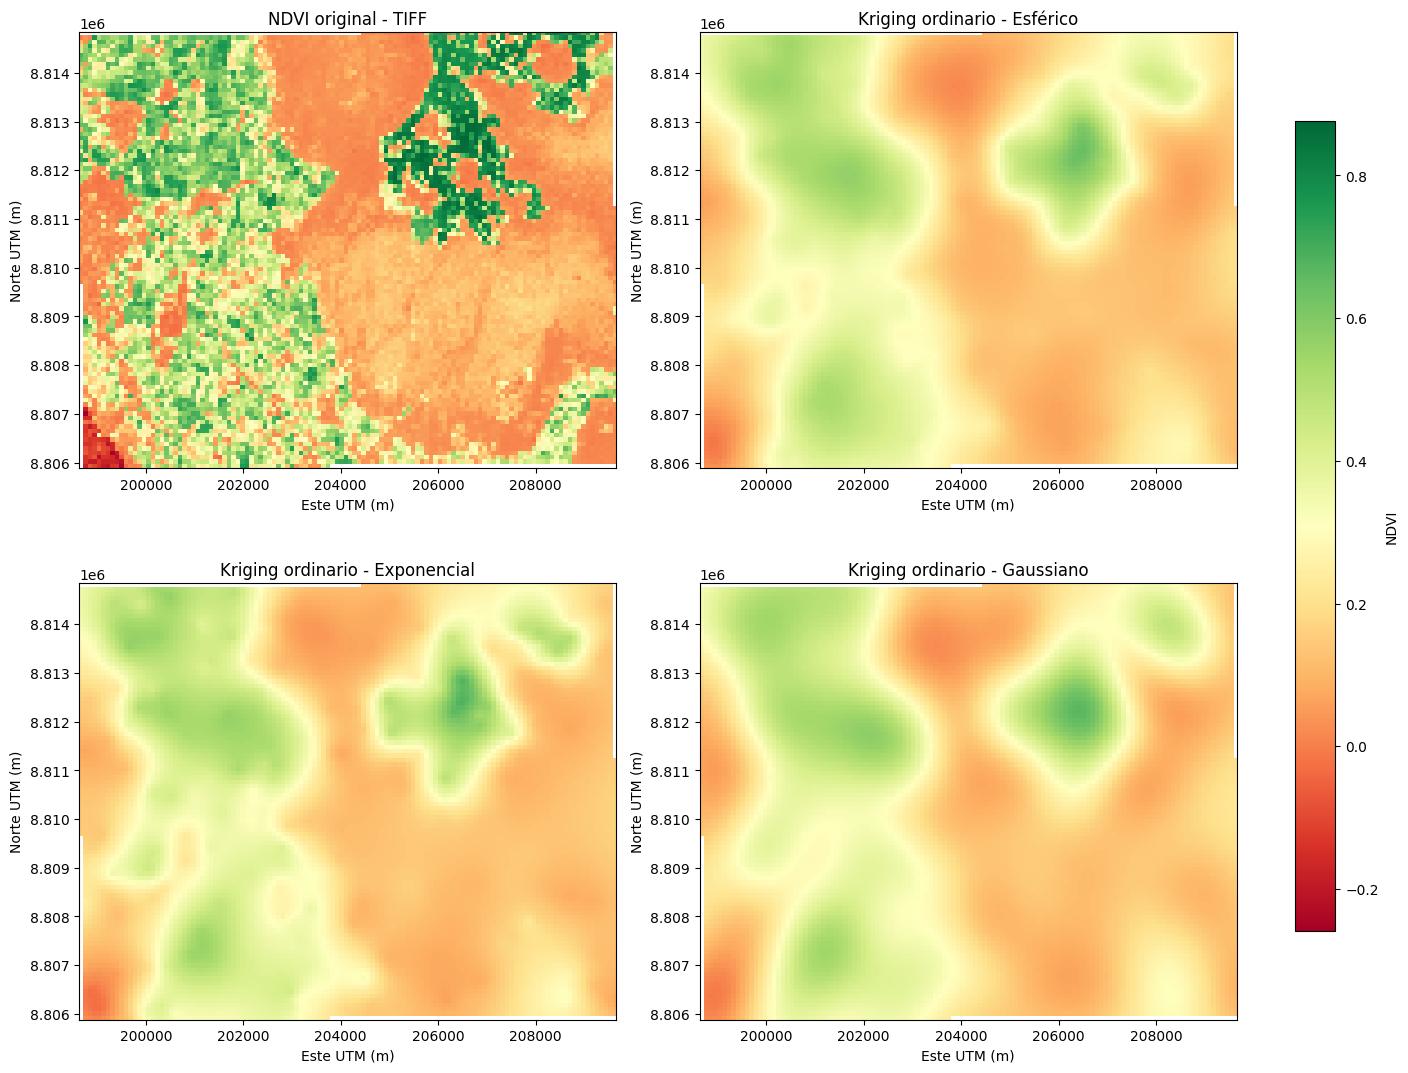

In [4]:
fig, axes = plt.subplots(
    2, 2, figsize=(14, 11),
    constrained_layout=True
)

vmin = np.nanmin(ref[valido])
vmax = np.nanmax(ref[valido])

extent = [xmin, xmax, ymin, ymax]

# TIFF original
im = axes[0, 0].imshow(
    np.where(valido, ref, np.nan),
    extent=extent,
    origin='lower',
    cmap='RdYlGn',
    vmin=vmin,
    vmax=vmax
)

axes[0, 0].set_title('NDVI original - TIFF')

# Modelos Kriging
for ax, (nombre, pred) in zip(
    [axes[0, 1], axes[1, 0], axes[1, 1]],
    predicciones_ok.items()
):

    ax.imshow(
        np.where(valido, pred, np.nan),
        extent=extent,
        origin='lower',
        cmap='RdYlGn',
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(f'Kriging ordinario - {nombre}')

for ax in axes.flat:
    ax.set_xlabel('Este UTM (m)')
    ax.set_ylabel('Norte UTM (m)')

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.75,
    label='NDVI'
)

plt.show()

#Comparación de métricas

In [7]:
metricas = ['RMSE', 'MAE', 'R2_prediccion']

print('Ranking según RMSE:')
display(
    comparacion_ok[
        ['Modelo', 'RMSE', 'MAE',
         'R2_prediccion', 'R2_variograma']
    ].round(5)
)

Ranking según RMSE:


,Modelo,RMSE,MAE,R2_prediccion,R2_variograma
1,Exponencial,0.19974,0.15018,0.39809,0.93828
0,Esférico,0.20363,0.15444,0.37439,0.90076
2,Gaussiano,0.20569,0.15552,0.36169,0.89101


# Mapas de error de los tres modelos

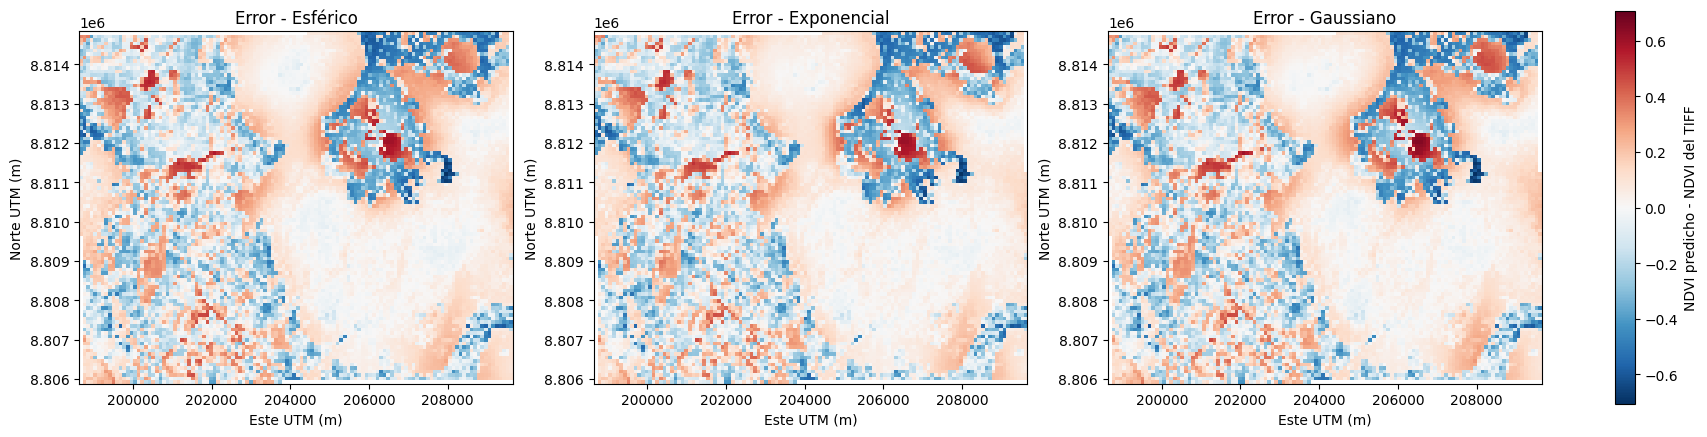

In [8]:
fig, axes = plt.subplots(
    1, 3, figsize=(17, 5),
    constrained_layout=True
)

errores = {
    nombre: np.where(valido, pred - ref, np.nan)
    for nombre, pred in predicciones_ok.items()
}

limite = max(
    np.nanmax(np.abs(error))
    for error in errores.values()
)

for ax, (nombre, error) in zip(axes, errores.items()):

    im = ax.imshow(
        error,
        extent=[xmin, xmax, ymin, ymax],
        origin='lower',
        cmap='RdBu_r',
        vmin=-limite,
        vmax=limite
    )

    ax.set_title(f'Error - {nombre}')
    ax.set_xlabel('Este UTM (m)')
    ax.set_ylabel('Norte UTM (m)')

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.8,
    label='NDVI predicho - NDVI del TIFF'
)

plt.show()

# Optimización del Kriging ordinario

In [12]:
from sklearn.model_selection import GroupKFold
from itertools import product
from tqdm.auto import tqdm

# Valores a evaluar
bins_opciones = range(5, 26)
lag_opciones = np.arange(40, 71) / 100

diagonal = np.sqrt(
    (x.max() - x.min())**2 +
    (y.max() - y.min())**2
)

# Bloques espaciales 4x4
bloque_x = np.minimum(
    ((x - x.min()) / (np.ptp(x) + 1e-10) * 4).astype(int),
    3
)

bloque_y = np.minimum(
    ((y - y.min()) / (np.ptp(y) + 1e-10) * 4).astype(int),
    3
)

grupos = bloque_x + 4 * bloque_y

cv = GroupKFold(n_splits=4)
particiones = list(cv.split(x, z, groups=grupos))

# Resultados
resultados_cv = []
configuraciones = {}

# Combinaciones
combinaciones = list(product(
    bins_opciones,
    lag_opciones
))

for n_bins_cv, fraccion in tqdm(
    combinaciones,
    desc='Optimizando Kriging'
):

    max_lag_cv = fraccion * diagonal

    # Predicciones de cada modelo
    predicciones_cv = {
        nombre: np.full(len(z), np.nan)
        for nombre in modelos
    }

    modelos_validos = {
        nombre: True
        for nombre in modelos
    }

    for train_idx, test_idx in particiones:

        x_train = x[train_idx]
        y_train = y[train_idx]
        z_train = z[train_idx]

        x_test = x[test_idx]
        y_test = y[test_idx]

        # Variograma experimental
        dist_cv, gamma_cv = variograma_experimental(
            x_train,
            y_train,
            z_train,
            max_lag=max_lag_cv,
            n_bins=n_bins_cv
        )

        if len(dist_cv) < 4:
            for nombre in modelos:
                modelos_validos[nombre] = False
            break

        sill_est = max(np.var(z_train), 1e-8)

        p0 = [
            0.1 * sill_est,
            sill_est,
            0.6 * dist_cv.max()
        ]

        bounds_cv = (
            [0, 0, 1],
            [
                3 * sill_est,
                3 * sill_est,
                2 * max_lag_cv
            ]
        )

        # Ajustar los tres modelos
        for nombre, modelo in modelos.items():

            if not modelos_validos[nombre]:
                continue

            try:

                popt, _ = curve_fit(
                    modelo,
                    dist_cv,
                    gamma_cv,
                    p0=p0,
                    bounds=bounds_cv,
                    maxfev=20000
                )

                nugget, sill, rango = popt

                if sill <= nugget:
                    modelos_validos[nombre] = False
                    continue

                modelo_pykrige = {
                    'Esférico': 'spherical',
                    'Exponencial': 'exponential',
                    'Gaussiano': 'gaussian'
                }[nombre]

                if nombre == 'Gaussiano':
                    rango = rango * 7 / (4 * np.sqrt(3))

                # Kriging ordinario
                ok_cv = OrdinaryKriging(
                    x_train,
                    y_train,
                    z_train,
                    variogram_model=modelo_pykrige,
                    variogram_parameters={
                        'sill': sill,
                        'range': rango,
                        'nugget': nugget
                    },
                    verbose=False,
                    enable_plotting=False
                )

                pred_test, _ = ok_cv.execute(
                    'points',
                    x_test,
                    y_test
                )

                predicciones_cv[nombre][test_idx] = (
                    np.asarray(pred_test)
                )

            except (
                ValueError,
                RuntimeError,
                np.linalg.LinAlgError
            ):
                modelos_validos[nombre] = False

    # Evaluar configuraciones completas
    for nombre in modelos:

        pred_cv = predicciones_cv[nombre]

        if not modelos_validos[nombre]:
            continue

        if not np.all(np.isfinite(pred_cv)):
            continue

        rmse_cv = np.sqrt(
            mean_squared_error(z, pred_cv)
        )

        mae_cv = mean_absolute_error(z, pred_cv)
        r2_cv = r2_score(z, pred_cv)

        resultados_cv.append({
            'Modelo': nombre,
            'n_bins': n_bins_cv,
            'max_lag_frac': round(float(fraccion), 2),
            'RMSE_CV': rmse_cv,
            'MAE_CV': mae_cv,
            'R2_CV': r2_cv
        })

        configuraciones[
            (nombre, n_bins_cv, round(float(fraccion), 2))
        ] = pred_cv.copy()

# Tabla final
tabla_cv = pd.DataFrame(resultados_cv)

if tabla_cv.empty:
    raise ValueError(
        'No se encontraron configuraciones válidas.'
    )

tabla_cv = tabla_cv.sort_values(
    'RMSE_CV'
).reset_index(drop=True)

print('Configuraciones evaluadas:', 1953)
print('Configuraciones válidas:', len(tabla_cv))

print('\nMEJORES 20 CONFIGURACIONES')
display(tabla_cv.head(20).round(5))

print('\nMEJOR CONFIGURACIÓN')
display(tabla_cv.head(1).round(5))

# Comparación con la configuración anterior
print('\nCONFIGURACIÓN ANTERIOR (20 bins, 50%)')

display(
    tabla_cv[
        (tabla_cv['n_bins'] == 20) &
        (np.isclose(tabla_cv['max_lag_frac'], 0.50))
    ].round(5)
)

Optimizando Kriging:   0%|          | 0/651 [00:00<?, ?it/s]

Configuraciones evaluadas: 1953
Configuraciones válidas: 1953

MEJORES 20 CONFIGURACIONES


,Modelo,n_bins,max_lag_frac,RMSE_CV,MAE_CV,R2_CV
0,Exponencial,19,0.45,0.23140,0.19201,0.16273
1,Exponencial,20,0.45,0.23141,0.19205,0.16269
2,Exponencial,22,0.50,0.23142,0.19211,0.16262
3,Exponencial,21,0.47,0.23148,0.19229,0.16218
4,Exponencial,22,0.51,0.23154,0.19226,0.16170
5,Exponencial,20,0.47,0.23156,0.19230,0.16159
6,Exponencial,20,0.46,0.23157,0.19239,0.16154
7,Exponencial,23,0.45,0.23157,0.19250,0.16151
8,Exponencial,21,0.48,0.23157,0.19238,0.16147
9,Exponencial,22,0.49,0.23159,0.19244,0.16135



MEJOR CONFIGURACIÓN


,Modelo,n_bins,max_lag_frac,RMSE_CV,MAE_CV,R2_CV
0,Exponencial,19,0.45,0.2314,0.19201,0.16273



CONFIGURACIÓN ANTERIOR (20 bins, 50%)


,Modelo,n_bins,max_lag_frac,RMSE_CV,MAE_CV,R2_CV
84,Exponencial,20,0.5,0.23230,0.19335,0.15618
1000,Gaussiano,20,0.5,0.23833,0.19744,0.11181
1489,Esférico,20,0.5,0.24061,0.20074,0.09474


#Ajustar el mejor modelo con los 300 puntos

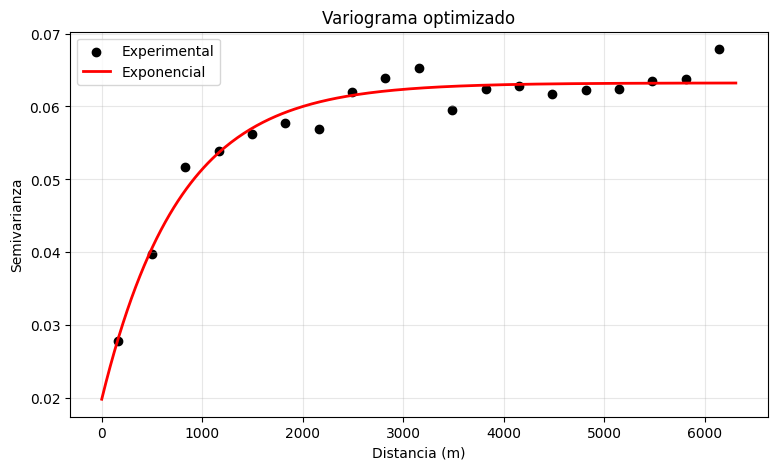

Modelo: Exponencial
n_bins: 19
max_lag: 6306.478465883731
Nugget: 0.01984202024518179
Sill: 0.06323298487197786
Rango: 2309.036550338373


In [13]:
# Mejor configuración
mejor = tabla_cv.iloc[0]

nombre_opt = mejor['Modelo']
bins_opt = int(mejor['n_bins'])
lag_opt = float(mejor['max_lag_frac'])

max_lag_opt = lag_opt * diagonal

# Variograma experimental completo
dist_opt, gamma_opt = variograma_experimental(
    x, y, z,
    max_lag=max_lag_opt,
    n_bins=bins_opt
)

# Ajuste teórico final
sill_est = max(np.var(z), 1e-8)

popt_opt, _ = curve_fit(
    modelos[nombre_opt],
    dist_opt,
    gamma_opt,
    p0=[
        0.1 * sill_est,
        sill_est,
        0.6 * dist_opt.max()
    ],
    bounds=(
        [0, 0, 1],
        [
            3 * sill_est,
            3 * sill_est,
            2 * max_lag_opt
        ]
    ),
    maxfev=20000
)

nugget_opt, sill_opt, rango_opt = popt_opt

if sill_opt <= nugget_opt:
    raise ValueError(
        'El ajuste final tiene sill <= nugget. '
        'Revisar el variograma.'
    )

# Gráfico del variograma
dist_linea = np.linspace(0, max_lag_opt, 300)

plt.figure(figsize=(9, 5))

plt.scatter(
    dist_opt,
    gamma_opt,
    color='black',
    label='Experimental'
)

plt.plot(
    dist_linea,
    modelos[nombre_opt](
        dist_linea,
        *popt_opt
    ),
    color='red',
    linewidth=2,
    label=nombre_opt
)

plt.xlabel('Distancia (m)')
plt.ylabel('Semivarianza')
plt.title('Variograma optimizado')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Conversión de parámetros
rango_pykrige = rango_opt

if nombre_opt == 'Gaussiano':
    rango_pykrige *= 7 / (4 * np.sqrt(3))

modelo_pykrige = {
    'Esférico': 'spherical',
    'Exponencial': 'exponential',
    'Gaussiano': 'gaussian'
}[nombre_opt]

# Kriging ordinario optimizado
ok_optimizado = OrdinaryKriging(
    x, y, z,
    variogram_model=modelo_pykrige,
    variogram_parameters={
        'sill': sill_opt,
        'range': rango_pykrige,
        'nugget': nugget_opt
    },
    verbose=False,
    enable_plotting=False
)

Zopt, Vopt = ok_optimizado.execute(
    'grid',
    gridx,
    gridy
)

Zopt = np.asarray(Zopt)
Vopt = np.asarray(Vopt)

print('Modelo:', nombre_opt)
print('n_bins:', bins_opt)
print('max_lag:', max_lag_opt)
print('Nugget:', nugget_opt)
print('Sill:', sill_opt)
print('Rango:', rango_opt)

# Comparación del Kriging optimizado con el anterior

,Modelo,RMSE,MAE,R2
0,OK anterior,0.19974,0.15018,0.39809
1,OK optimizado,0.19841,0.14690,0.40608


Cambio porcentual del RMSE: 0.67%


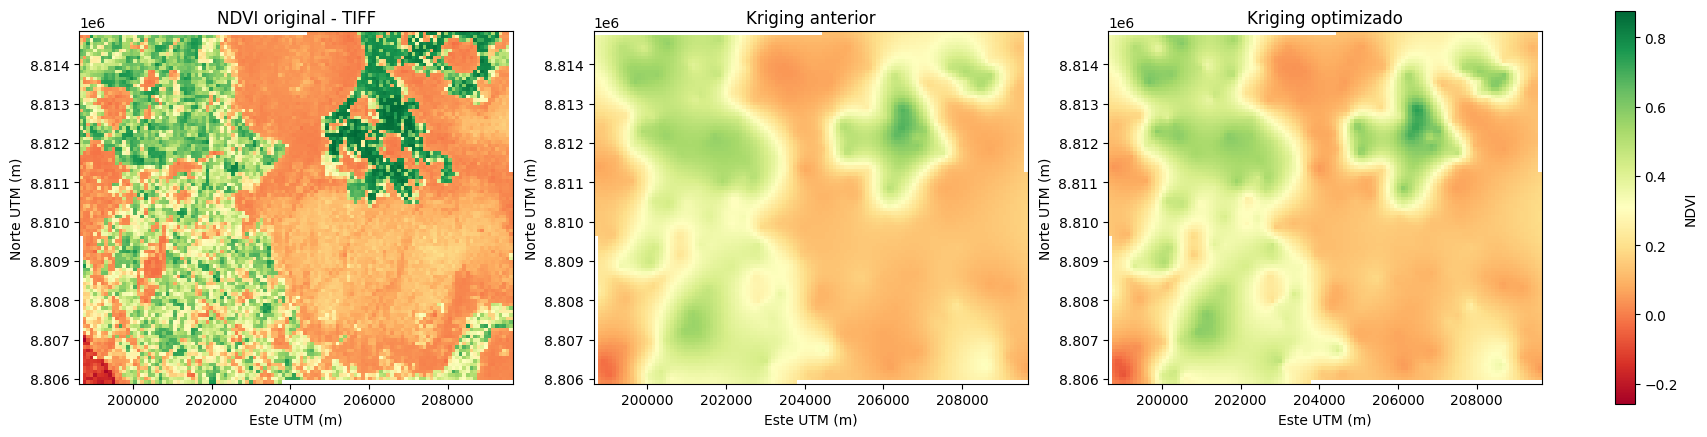

In [14]:
# Predicción del mejor modelo anterior
nombre_anterior = comparacion_ok.iloc[0]['Modelo']
Zanterior = predicciones_ok[nombre_anterior]

# Evaluación sobre los mismos píxeles
mask = (
    valido &
    np.isfinite(Zanterior) &
    np.isfinite(Zopt)
)

observado = ref[mask]

comparacion_final = pd.DataFrame([
    {
        'Modelo': 'OK anterior',
        'RMSE': np.sqrt(mean_squared_error(
            observado, Zanterior[mask]
        )),
        'MAE': mean_absolute_error(
            observado, Zanterior[mask]
        ),
        'R2': r2_score(
            observado, Zanterior[mask]
        )
    },
    {
        'Modelo': 'OK optimizado',
        'RMSE': np.sqrt(mean_squared_error(
            observado, Zopt[mask]
        )),
        'MAE': mean_absolute_error(
            observado, Zopt[mask]
        ),
        'R2': r2_score(
            observado, Zopt[mask]
        )
    }
])

display(comparacion_final.round(5))

# Reducción porcentual del RMSE
rmse_anterior = comparacion_final.iloc[0]['RMSE']
rmse_optimizado = comparacion_final.iloc[1]['RMSE']

mejora = (
    (rmse_anterior - rmse_optimizado) /
    rmse_anterior * 100
)

print(f'Cambio porcentual del RMSE: {mejora:.2f}%')

# Mapas comparativos
fig, axes = plt.subplots(
    1, 3, figsize=(17, 5),
    constrained_layout=True
)

imagenes = [
    ref,
    Zanterior,
    Zopt
]

titulos = [
    'NDVI original - TIFF',
    'Kriging anterior',
    'Kriging optimizado'
]

vmin = np.nanmin(ref[valido])
vmax = np.nanmax(ref[valido])

for ax, imagen, titulo in zip(
    axes, imagenes, titulos
):

    im = ax.imshow(
        np.where(valido, imagen, np.nan),
        extent=[xmin, xmax, ymin, ymax],
        origin='lower',
        cmap='RdYlGn',
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(titulo)
    ax.set_xlabel('Este UTM (m)')
    ax.set_ylabel('Norte UTM (m)')

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.8,
    label='NDVI'
)

plt.show()

## Modelos de ML

coordenadas UTM como variables predictoras

In [17]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from scipy.spatial.distance import cdist
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Coordenadas y variable respuesta
X = np.column_stack((x, y))
Y = np.asarray(z, dtype=float)

# Misma validación espacial del OK
# Se reutiliza 'particiones' de la optimización anterior
print("Observaciones:", len(Y))
print("Particiones espaciales:", len(particiones))

# Predicciones de validación
pred_rf = np.full(len(Y), np.nan)
pred_rfk = np.full(len(Y), np.nan)
pred_deep = np.full(len(Y), np.nan)

# Predicciones del OK optimizado en validación cruzada
clave_ok = (
    nombre_opt,
    bins_opt,
    round(lag_opt, 2)
)

pred_ok_cv = configuraciones[clave_ok].copy()

# Métricas
def evaluar(y_real, y_pred, nombre):
    return {
        'Modelo': nombre,
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
        'MAE': mean_absolute_error(y_real, y_pred),
        'R2': r2_score(y_real, y_pred)
    }

Observaciones: 300
Particiones espaciales: 4


## RF

In [18]:
for train_idx, test_idx in particiones:

    rf = RandomForestRegressor(
        n_estimators=300,
        max_features=1.0,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X[train_idx], Y[train_idx])

    pred_rf[test_idx] = rf.predict(X[test_idx])

print("Random Forest completado")

display(pd.DataFrame([
    evaluar(Y, pred_rf, 'Random Forest')
]).round(5))

Random Forest completado


,Modelo,RMSE,MAE,R2
0,Random Forest,0.23711,0.18384,0.12087


## Random Forest Kriging

In [19]:
for train_idx, test_idx in particiones:

    X_train = X[train_idx]
    Y_train = Y[train_idx]

    X_test = X[test_idx]

    # Residuos fuera de muestra dentro del entrenamiento
    residuos = np.full(len(Y_train), np.nan)

    cv_interno = KFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    for tr, val in cv_interno.split(X_train):

        rf_interno = RandomForestRegressor(
            n_estimators=300,
            max_features=1.0,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )

        rf_interno.fit(
            X_train[tr],
            Y_train[tr]
        )

        residuos[val] = rf_interno.predict(
            X_train[val]
        )

    residuos = Y_train - residuos

    # RF con todo el entrenamiento externo
    rf = RandomForestRegressor(
        n_estimators=300,
        max_features=1.0,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, Y_train)

    pred_base = rf.predict(X_test)

    # Kriging de residuos
    ok_residuos = OrdinaryKriging(
        X_train[:, 0],
        X_train[:, 1],
        residuos,
        variogram_model='exponential',
        nlags=19,
        verbose=False,
        enable_plotting=False
    )

    pred_residuos, _ = ok_residuos.execute(
        'points',
        X_test[:, 0],
        X_test[:, 1]
    )

    pred_rfk[test_idx] = (
        pred_base + np.asarray(pred_residuos)
    )

print("Random Forest Kriging completado")

display(pd.DataFrame([
    evaluar(Y, pred_rfk, 'Random Forest Kriging')
]).round(5))

Random Forest Kriging completado


,Modelo,RMSE,MAE,R2
0,Random Forest Kriging,0.23193,0.18059,0.1589


## DeepKriging

In [20]:
# Centros espaciales de las funciones de base
# 10 x 10 = 100 funciones RBF

centros_x = np.linspace(xmin, xmax, 10)
centros_y = np.linspace(ymin, ymax, 10)

CX, CY = np.meshgrid(centros_x, centros_y)

centros = np.column_stack([
    CX.ravel(),
    CY.ravel()
])

# Escala espacial de las bases
escala_rbf = diagonal / 10

for train_idx, test_idx in particiones:

    X_train = X[train_idx]
    X_test = X[test_idx]

    Y_train = Y[train_idx]

    # Normalizar coordenadas usando solo entrenamiento
    scaler_x = StandardScaler()

    X_train_scaled = scaler_x.fit_transform(X_train)
    X_test_scaled = scaler_x.transform(X_test)

    # Funciones de base espacial
    B_train = np.exp(
        -0.5 * (
            cdist(X_train, centros) / escala_rbf
        )**2
    )

    B_test = np.exp(
        -0.5 * (
            cdist(X_test, centros) / escala_rbf
        )**2
    )

    # Coordenadas + funciones espaciales
    X_deep_train = np.column_stack([
        X_train_scaled,
        B_train
    ])

    X_deep_test = np.column_stack([
        X_test_scaled,
        B_test
    ])

    # Normalización del NDVI
    scaler_y = StandardScaler()

    Y_train_scaled = scaler_y.fit_transform(
        Y_train.reshape(-1, 1)
    ).ravel()

    # Red neuronal
    deep = MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=1500,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=40,
        random_state=42
    )

    deep.fit(
        X_deep_train,
        Y_train_scaled
    )

    pred_scaled = deep.predict(X_deep_test)

    pred_deep[test_idx] = scaler_y.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).ravel()

print("DeepKriging completado")

display(pd.DataFrame([
    evaluar(Y, pred_deep, 'DeepKriging')
]).round(5))

DeepKriging completado


,Modelo,RMSE,MAE,R2
0,DeepKriging,0.24,0.18717,0.09931


## Comparación de los cuatro modelos

,Modelo,RMSE,MAE,R2
0,Ordinary Kriging,0.23140,0.19201,0.16273
1,Random Forest Kriging,0.23193,0.18059,0.15890
2,Random Forest,0.23711,0.18384,0.12087
3,DeepKriging,0.24000,0.18717,0.09931


Mejor modelo: Ordinary Kriging


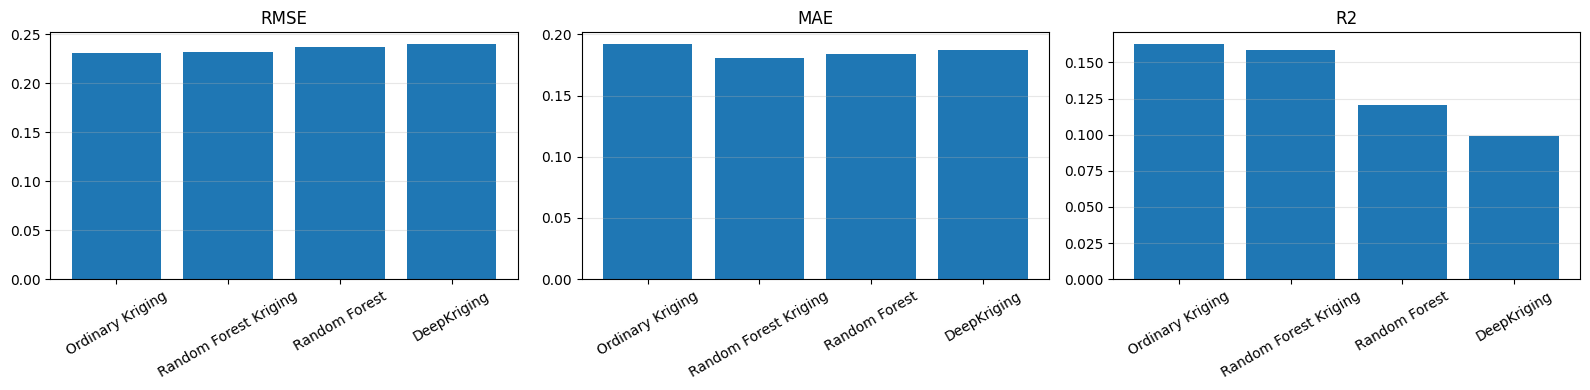

In [21]:
comparacion_ml = pd.DataFrame([
    evaluar(Y, pred_ok_cv, 'Ordinary Kriging'),
    evaluar(Y, pred_rf, 'Random Forest'),
    evaluar(Y, pred_rfk, 'Random Forest Kriging'),
    evaluar(Y, pred_deep, 'DeepKriging')
])

comparacion_ml = comparacion_ml.sort_values(
    'RMSE'
).reset_index(drop=True)

display(comparacion_ml.round(5))

print(
    "Mejor modelo:",
    comparacion_ml.iloc[0]['Modelo']
)

# Gráficos de comparación
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metrica in zip(
    axes,
    ['RMSE', 'MAE', 'R2']
):

    ax.bar(
        comparacion_ml['Modelo'],
        comparacion_ml[metrica]
    )

    ax.set_title(metrica)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

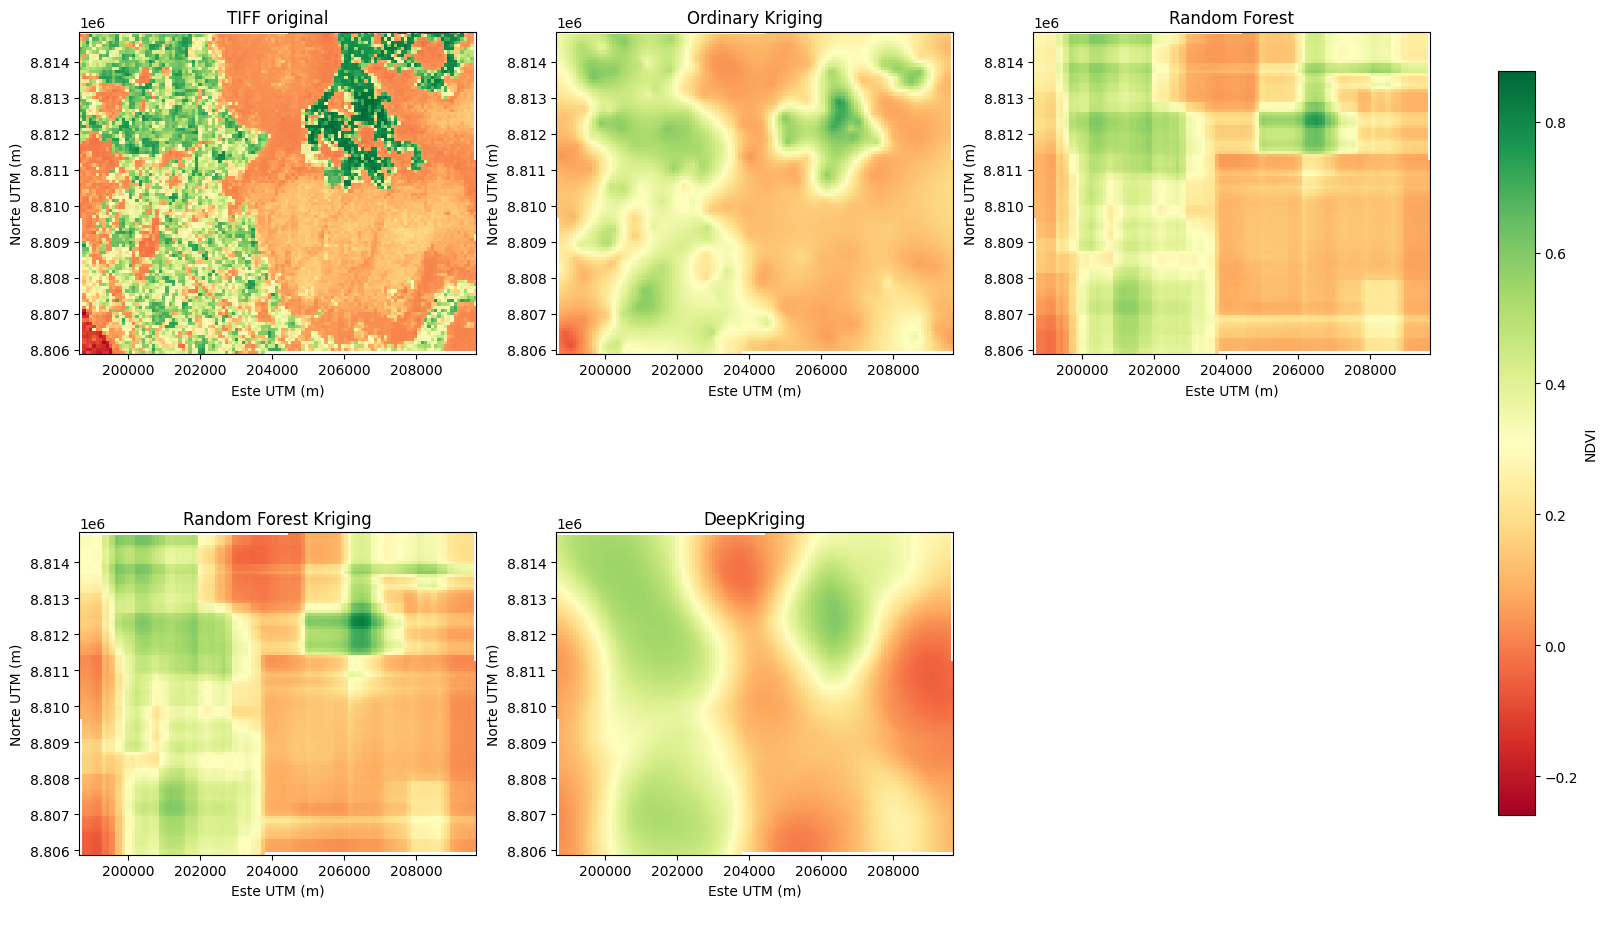

In [24]:
# RF final
rf_final = RandomForestRegressor(
    n_estimators=300,
    max_features=1.0,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)
rf_final.fit(X, Y)

# Residuos RF fuera de muestra
residuos_final = np.full(len(Y), np.nan)

cv_interno = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

for tr, val in cv_interno.split(X):
    rf_aux = RandomForestRegressor(
        n_estimators=300,
        max_features=1.0,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
    rf_aux.fit(X[tr], Y[tr])
    residuos_final[val] = Y[val] - rf_aux.predict(X[val])

ok_res_final = OrdinaryKriging(
    x, y, residuos_final,
    variogram_model='exponential',
    nlags=19,
    verbose=False,
    enable_plotting=False
)

# DeepKriging final
scaler_x_final = StandardScaler()
X_scaled = scaler_x_final.fit_transform(X)

B = np.exp(
    -0.5 * (cdist(X, centros) / escala_rbf)**2
)

X_deep = np.column_stack([X_scaled, B])

scaler_y_final = StandardScaler()
Y_scaled = scaler_y_final.fit_transform(
    Y.reshape(-1, 1)
).ravel()

deep_final = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    alpha=0.01,
    learning_rate_init=0.001,
    max_iter=1500,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=40,
    random_state=42
)
deep_final.fit(X_deep, Y_scaled)

# Grilla
GX, GY = np.meshgrid(gridx, gridy)
X_grid = np.column_stack([GX.ravel(), GY.ravel()])

# Predicciones
Z_rf = rf_final.predict(X_grid).reshape(GX.shape)

res_grid, _ = ok_res_final.execute(
    'points',
    X_grid[:, 0],
    X_grid[:, 1]
)

Z_rfk = (
    Z_rf.ravel() + np.asarray(res_grid)
).reshape(GX.shape)

X_grid_scaled = scaler_x_final.transform(X_grid)

B_grid = np.exp(
    -0.5 * (
        cdist(X_grid, centros) / escala_rbf
    )**2
)

X_grid_deep = np.column_stack([
    X_grid_scaled,
    B_grid
])

Z_deep = scaler_y_final.inverse_transform(
    deep_final.predict(X_grid_deep).reshape(-1, 1)
).reshape(GX.shape)

# Superficies
superficies = {
    'TIFF original': ref,
    'Ordinary Kriging': Zopt,
    'Random Forest': Z_rf,
    'Random Forest Kriging': Z_rfk,
    'DeepKriging': Z_deep
}

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    constrained_layout=True
)

vmin = np.nanmin(ref[valido])
vmax = np.nanmax(ref[valido])

for ax, (nombre, superficie) in zip(
    axes.flat,
    superficies.items()
):

    im = ax.imshow(
        np.where(valido, superficie, np.nan),
        extent=[xmin, xmax, ymin, ymax],
        origin='lower',
        cmap='RdYlGn',
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(nombre)
    ax.set_xlabel('Este UTM (m)')
    ax.set_ylabel('Norte UTM (m)')

axes.flat[-1].axis('off')

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.75,
    label='NDVI'
)

plt.show()